In [ ]:
# Installing required libraries
!pip install torch torchvision albumentations scikit-learn matplotlib seaborn --quiet

# Importing required libraries
import torch
import torchvision
import albumentations as A
from albumentations import Compose, HorizontalFlip, VerticalFlip, Rotate, MotionBlur, GaussianBlur, Resize
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import numpy as np
import os
import cv2
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torch.optim as optim


# Setting Device (preferced GPU but can run on CPU )
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 73.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 109.4 MB/s eta 0:00:00
Using device: cuda


In [ ]:
# Mounting the google Drive

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Spillting the dataset into train, val and test with 70%, 15% and 15% ratio respectively
# Later saving it into drive for reuse

import os
import shutil
import random
from tqdm import tqdm

def split_dataset(source_dir, output_dir, split_ratio=(0.7, 0.15, 0.15), seed=42):
    random.seed(seed)
    assert sum(split_ratio) == 1.0, "Split ratios must sum to 1.0"
    classes = os.listdir(source_dir)

    for cls in tqdm(classes, desc="Processing classes"):
        class_dir = os.path.join(source_dir, cls)
        images = os.listdir(class_dir)
        random.shuffle(images)

        n_total = len(images)
        n_train = int(split_ratio[0] * n_total)
        n_val = int(split_ratio[1] * n_total)

        splits = {
            'train': images[:n_train],
            'val': images[n_train:n_train + n_val],
            'test': images[n_train + n_val:]
        }

        for split, files in splits.items():
            split_path = os.path.join(output_dir, split, cls)
            os.makedirs(split_path, exist_ok=True)
            for file in files:
                src_path = os.path.join(class_dir, file)
                dst_path = os.path.join(split_path, file)
                shutil.copy2(src_path, dst_path)

# Example usage (change to your actual paths, currently its according to my own need)
leaf_input = "/content/drive/MyDrive/datasets/Mango_Leaf_Dataset"
leaf_output = "/content/drive/MyDrive/datasets/Split_Leaves"
fruit_input = "/content/drive/MyDrive/datasets/Mango/train"
fruit_output = "/content/drive/MyDrive/datasets/Mango/Split_Fruits"

# Split leaves and fruits
split_dataset(leaf_input, leaf_output)
split_dataset(fruit_input, fruit_output)


print("Splitted Data into 70 as Training, 15 as Validation and 15  as training (no need to rerun it again )")

Splitted Data into 70 as Training, 15 as Validation and 15  as training (no need to rerun it again )


In [ ]:
# Testing either the split worked or not
!ls /content/drive/MyDrive/datasets/Split_Leaves/train
!ls /content/drive/MyDrive/datasets/Split_Leaves/val
!ls /content/drive/MyDrive/datasets/Split_Leaves/test


Anthracnose  Bacterial_Black_Spot  Healthy  Multiple
Anthracnose  Bacterial_Black_Spot  Healthy  Multiple
Anthracnose  Bacterial_Black_Spot  Healthy  Multiple


In [ ]:


# Defining all dataset directories
dataset_dirs = {
    "Leaf Train": "/content/drive/MyDrive/datasets/Split_Leaves/train",
    "Leaf Val": "/content/drive/MyDrive/datasets/Split_Leaves/val",
    "Leaf Test": "/content/drive/MyDrive/datasets/Split_Leaves/test",
    "Fruit Train": "/content/drive/MyDrive/datasets/Mango/Split_Fruits/train",
    "Fruit Val": "/content/drive/MyDrive/datasets/Mango/Split_Fruits/val",
    "Fruit Test": "/content/drive/MyDrive/datasets/Mango/Split_Fruits/test"
}

# Function to count images recursively through class folders
def count_images(directory):
    total = 0
    for class_folder in os.listdir(directory):
        class_path = os.path.join(directory, class_folder)
        if os.path.isdir(class_path):
            total += len([
                f for f in os.listdir(class_path)
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))
            ])
    return total

# Looping through each dataset split and counting images
for name, path in dataset_dirs.items():
    count = count_images(path)
    print(f"{name}: {count} images")


Leaf Train: 1645 images
Leaf Val: 351 images
Leaf Test: 357 images
Fruit Train: 1308 images
Fruit Val: 279 images
Fruit Test: 284 images


In [ ]:


# Dataset directories for both Leaf and Fruit
datasets = {
    "Leaf": {
        "Train": "/content/drive/MyDrive/datasets/Split_Leaves/train",
        "Validation": "/content/drive/MyDrive/datasets/Split_Leaves/val",
        "Test": "/content/drive/MyDrive/datasets/Split_Leaves/test"
    },
    "Fruit": {
        "Train": "/content/drive/MyDrive/datasets/Mango/Split_Fruits/train",
        "Validation": "/content/drive/MyDrive/datasets/Mango/Split_Fruits/val",
        "Test": "/content/drive/MyDrive/datasets/Mango/Split_Fruits/test"
    }
}

# Function to count images per class
def count_images_per_class(directory):
    class_counts = {}
    for class_folder in os.listdir(directory):
        class_path = os.path.join(directory, class_folder)
        if os.path.isdir(class_path):
            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ])
            class_counts[class_folder] = count
    return class_counts

# Count and print image numbers for each dataset and split
for dataset_name, splits in datasets.items():
    print(f"\n=== {dataset_name} Dataset ===")
    for split_name, split_path in splits.items():
        print(f"\n{split_name} Set:")
        class_counts = count_images_per_class(split_path)
        total = 0
        for class_name, count in sorted(class_counts.items()):
            print(f"  {class_name}: {count} images")
            total += count
        print(f"  Total images in {split_name}: {total}")



=== Leaf Dataset ===

Train Set:
  Anthracnose: 228 images
  Bacterial_Black_Spot: 251 images
  Healthy: 175 images
  Multiple: 991 images
  Total images in Train: 1645

Validation Set:
  Anthracnose: 48 images
  Bacterial_Black_Spot: 54 images
  Healthy: 37 images
  Multiple: 212 images
  Total images in Validation: 351

Test Set:
  Anthracnose: 50 images
  Bacterial_Black_Spot: 55 images
  Healthy: 38 images
  Multiple: 214 images
  Total images in Test: 357

=== Fruit Dataset ===

Train Set:
  Anthracnose: 162 images
  Bacterial_Black_Spot: 496 images
  Healthy: 215 images
  Multiple: 435 images
  Total images in Train: 1308

Validation Set:
  Anthracnose: 34 images
  Bacterial_Black_Spot: 106 images
  Healthy: 46 images
  Multiple: 93 images
  Total images in Validation: 279

Test Set:
  Anthracnose: 36 images
  Bacterial_Black_Spot: 107 images
  Healthy: 47 images
  Multiple: 94 images
  Total images in Test: 284


In [ ]:

IMG_SIZE = 224

# Original (unwrapped)
class_specific_transforms = {
    "Anthracnose": A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=25, p=0.8),
        A.MotionBlur(blur_limit=3, p=0.2),
    ]),
    "Bacterial_Black_Spot": A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.VerticalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=10, p=0.7),
    ]),
    "Healthy": A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.Rotate(limit=10, p=0.5),
        A.RandomBrightnessContrast(p=0.1),
    ]),
    "Multiple": A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(limit=30, p=0.8),
        A.MotionBlur(p=0.3)
    ]),
}

class_specific_fruit_transforms = {
    "Anthracnose": Compose([
        Resize(IMG_SIZE, IMG_SIZE),
        HorizontalFlip(p=0.5),
        MotionBlur(p=0.4),
        Rotate(limit=15, p=0.5)
    ]),
    "Bacterial_Black_Spot": Compose([
        Resize(IMG_SIZE, IMG_SIZE),
        VerticalFlip(p=0.5),
        GaussianBlur(p=0.4),
        Rotate(limit=10, p=0.4)
    ]),
    "Healthy": Compose([
        Resize(IMG_SIZE, IMG_SIZE),
        HorizontalFlip(p=0.3),
        VerticalFlip(p=0.3),
        Rotate(limit=5, p=0.3)
    ]),
    "Multiple": Compose([
        Resize(IMG_SIZE, IMG_SIZE),
        HorizontalFlip(p=0.5),
        VerticalFlip(p=0.5),
        Rotate(limit=20, p=0.5)
    ])
}

val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])

# Wrapper
def wrap_transform(transform):
    return lambda image: transform(image=image)["image"]

# Wrapped versions
wrapped_class_specific_transforms = {
    cls: wrap_transform(tfm) for cls, tfm in class_specific_transforms.items()
}

wrapped_class_specific_fruit_transforms = {
    cls: wrap_transform(tfm) for cls, tfm in class_specific_fruit_transforms.items()
}

wrapped_val_test_transform = wrap_transform(val_test_transform)


/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
import torch
import os
import cv2
from torch.utils.data import Dataset

class LeafDataset(Dataset):
    def __init__(self, root_dir, transform_dict=None):
        self.root_dir = root_dir
        self.transform_dict = transform_dict
        self.image_paths = []
        self.labels = []
        self.class_names = sorted(os.listdir(root_dir))

        for label_idx, class_name in enumerate(self.class_names):
            class_folder = os.path.join(root_dir, class_name)
            for img_file in os.listdir(class_folder):
                self.image_paths.append(os.path.join(class_folder, img_file))
                self.labels.append(label_idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        label = self.labels[idx]
        class_name = self.class_names[label]

        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Apply class-specific transform if provided
        if self.transform_dict and class_name in self.transform_dict:
            image = self.transform_dict[class_name](image)
        else:
            image = A.Resize(224, 224)(image=image)["image"]

        image = torch.tensor(image / 255.0, dtype=torch.float32).permute(2, 0, 1)
        return image, label


FruitDataset = LeafDataset

In [ ]:
# Leaf dataset paths
leaf_train_dir = "/content/drive/MyDrive/datasets/Split_Leaves/train"
leaf_val_dir   = "/content/drive/MyDrive/datasets/Split_Leaves/val"
leaf_test_dir  = "/content/drive/MyDrive/datasets/Split_Leaves/test"

# Fruit dataset paths
fruit_train_dir = "/content/drive/MyDrive/datasets/Mango/Split_Fruits/train"
fruit_val_dir   = "/content/drive/MyDrive/datasets/Mango/Split_Fruits/val"
fruit_test_dir  = "/content/drive/MyDrive/datasets/Mango/Split_Fruits/test"


In [ ]:
def visualize_leaf_class_augments(root_dir, class_specific_transforms, samples_per_class=5):
    import matplotlib.pyplot as plt
    import random
    import cv2
    import os

    class_names = os.listdir(root_dir)
    for class_name in class_names:
        class_path = os.path.join(root_dir, class_name)
        images = os.listdir(class_path)
        selected_imgs = random.sample(images, samples_per_class)
        transform = class_specific_transforms[class_name]

        plt.figure(figsize=(15, 6))
        for i, img_name in enumerate(selected_imgs):
            img_path = os.path.join(class_path, img_name)
            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            augmented = transform(image=image)['image']

            # Show original
            plt.subplot(2, samples_per_class, i + 1)
            plt.imshow(image)
            plt.title("Original")
            plt.axis('off')

            # Show augmented
            plt.subplot(2, samples_per_class, i + 1 + samples_per_class)
            plt.imshow(augmented)
            plt.title("Augmented")
            plt.axis('off')

        plt.suptitle(f"Original vs Augmented Samples for Class: {class_name}", fontsize=16)
        plt.tight_layout()
        plt.show()


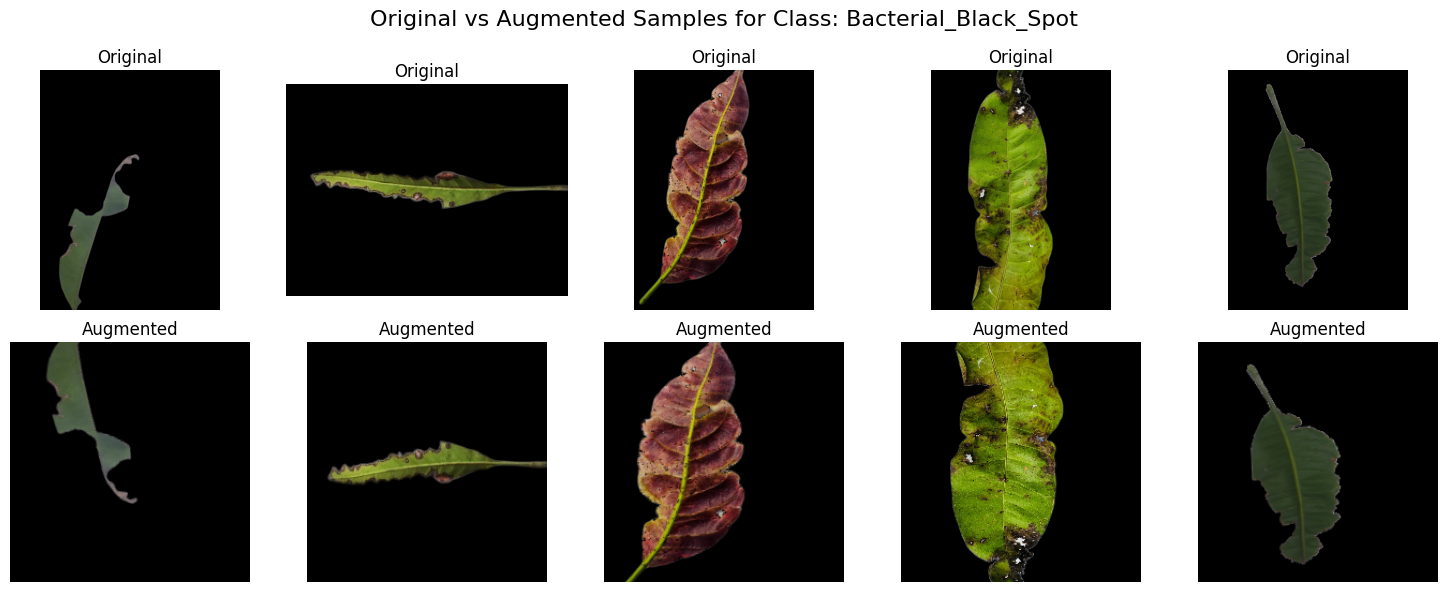

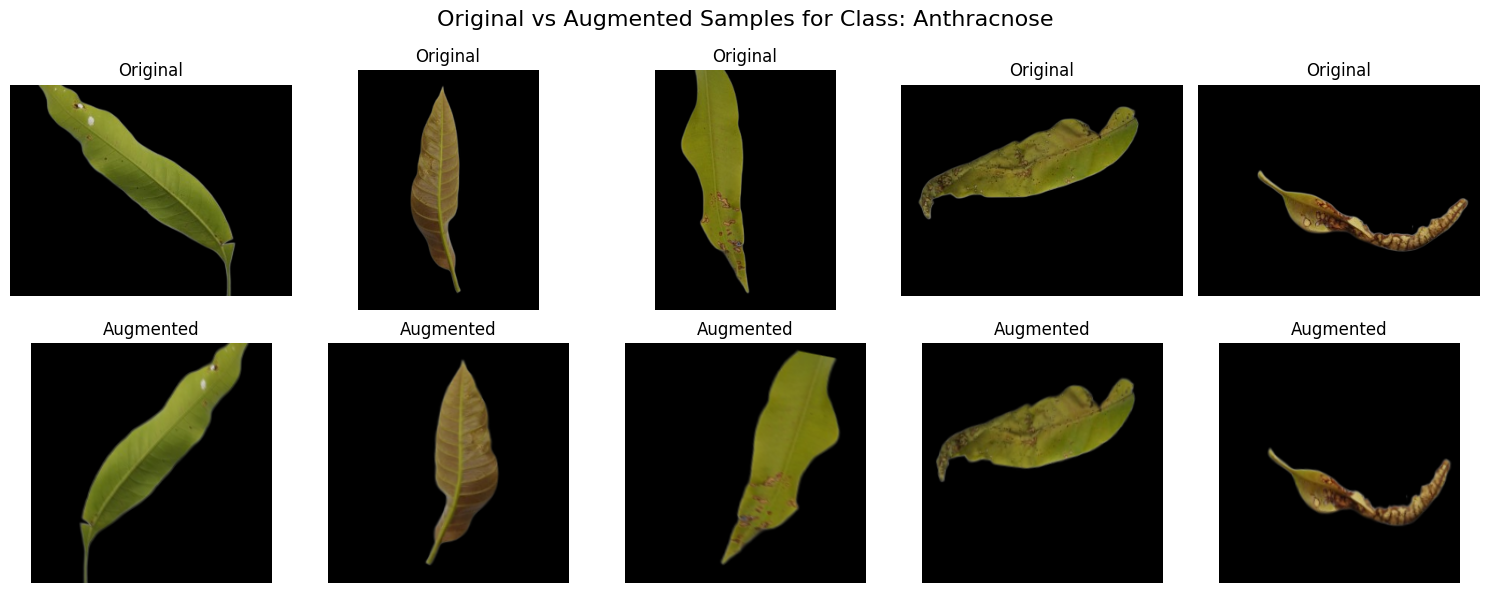

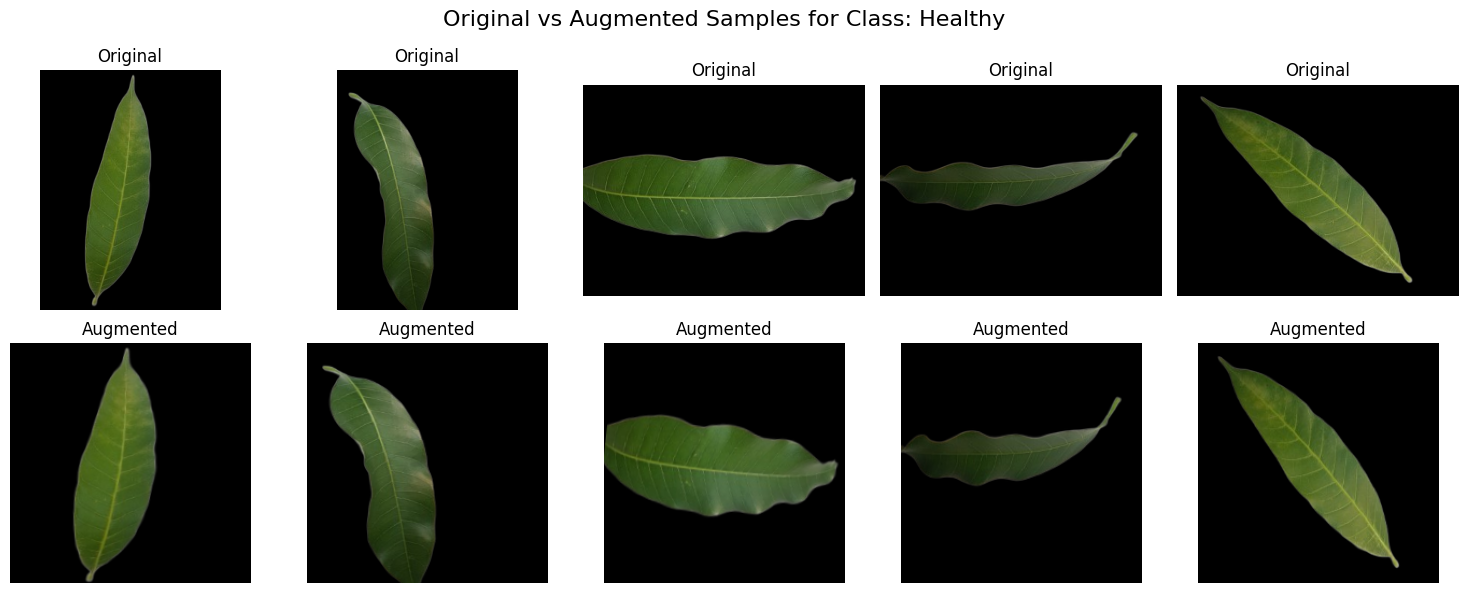

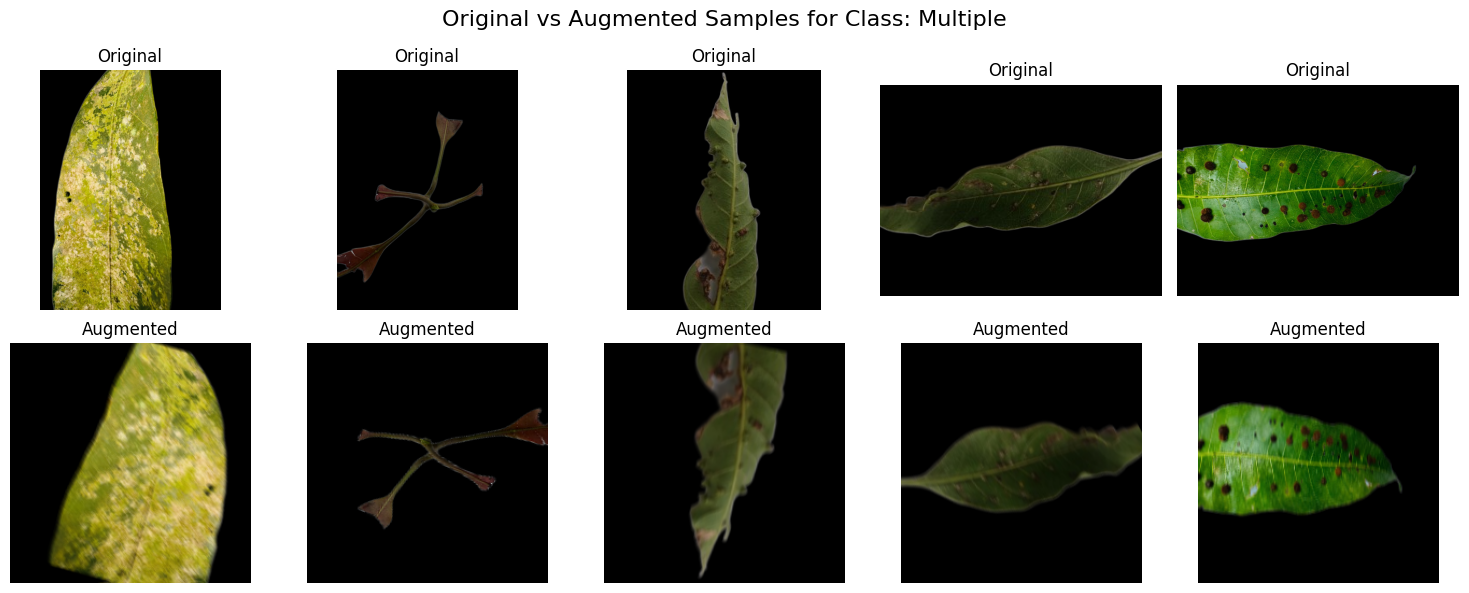

In [ ]:
visualize_leaf_class_augments(leaf_train_dir, class_specific_transforms, samples_per_class=5)


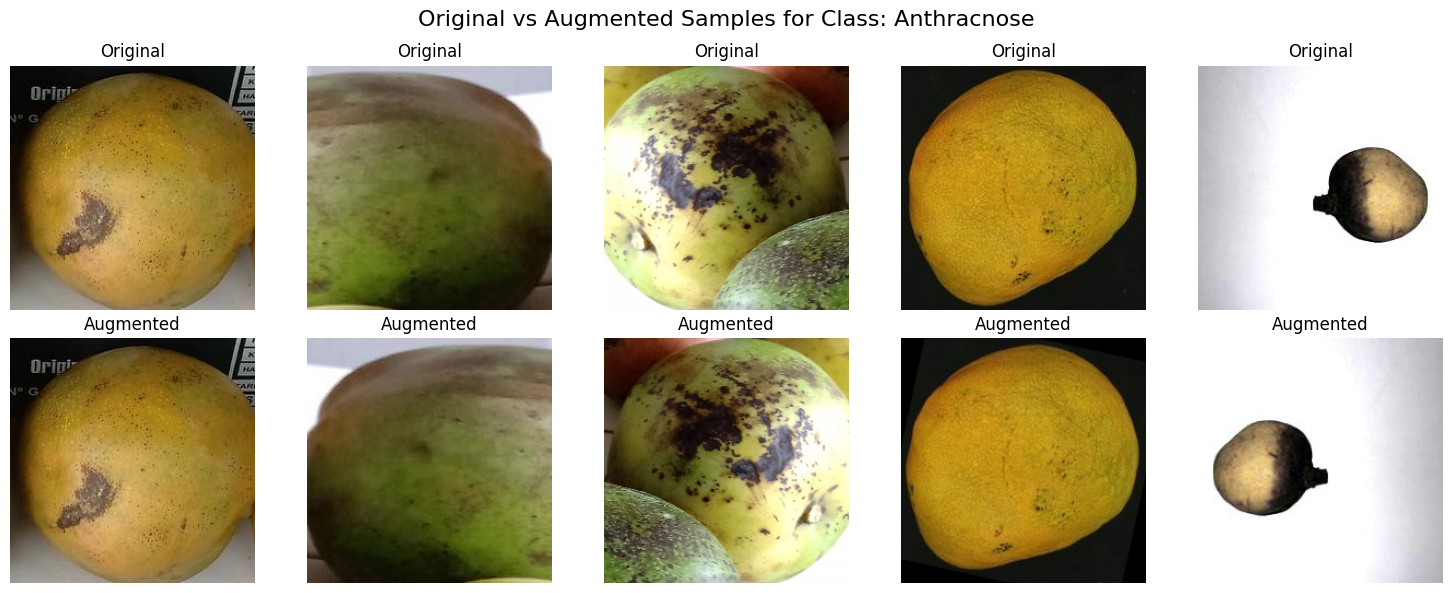

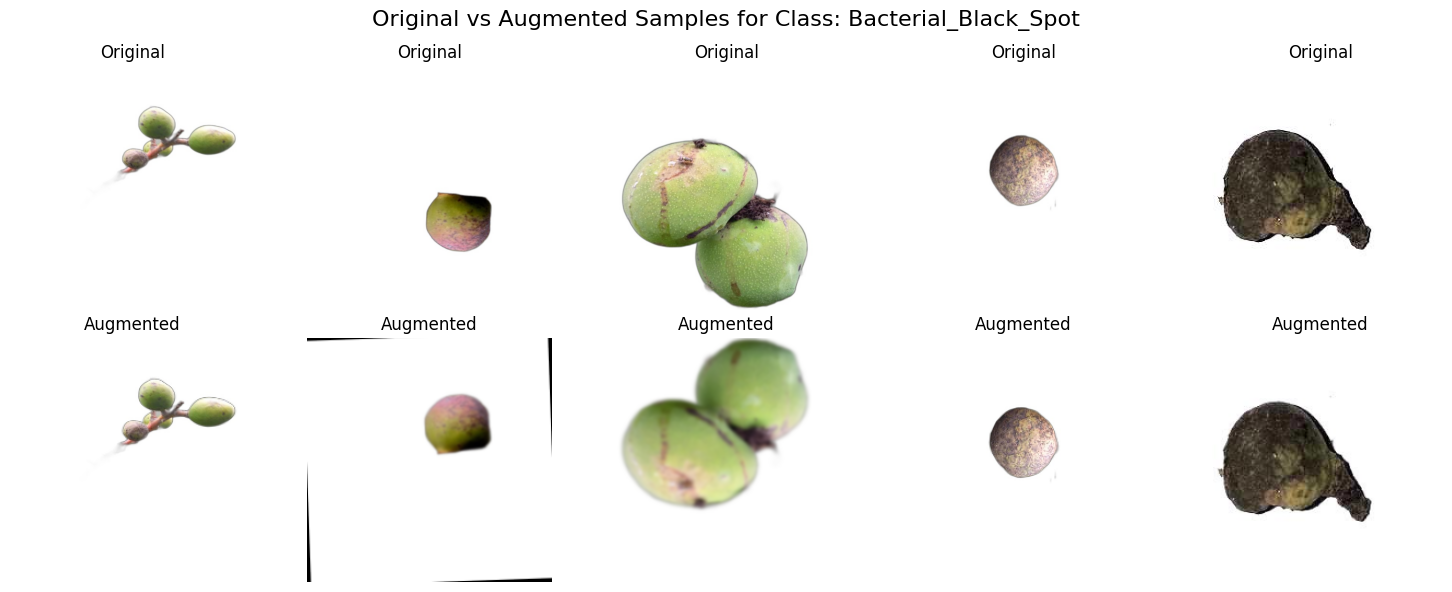

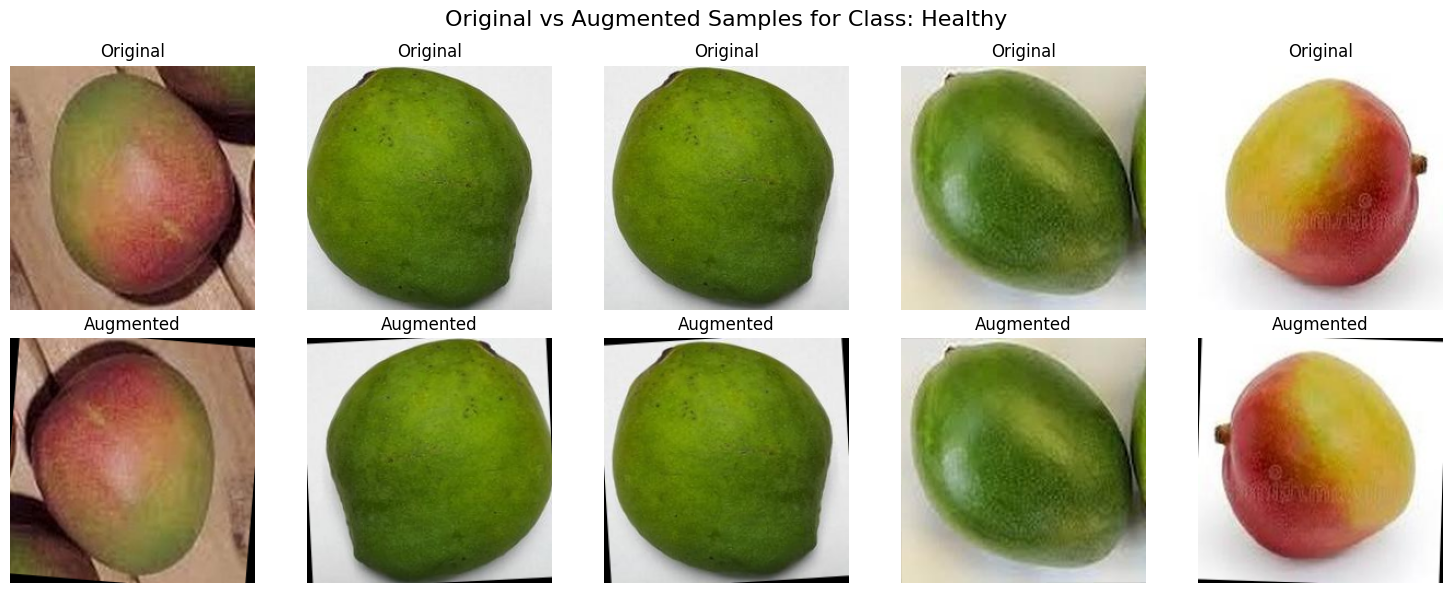

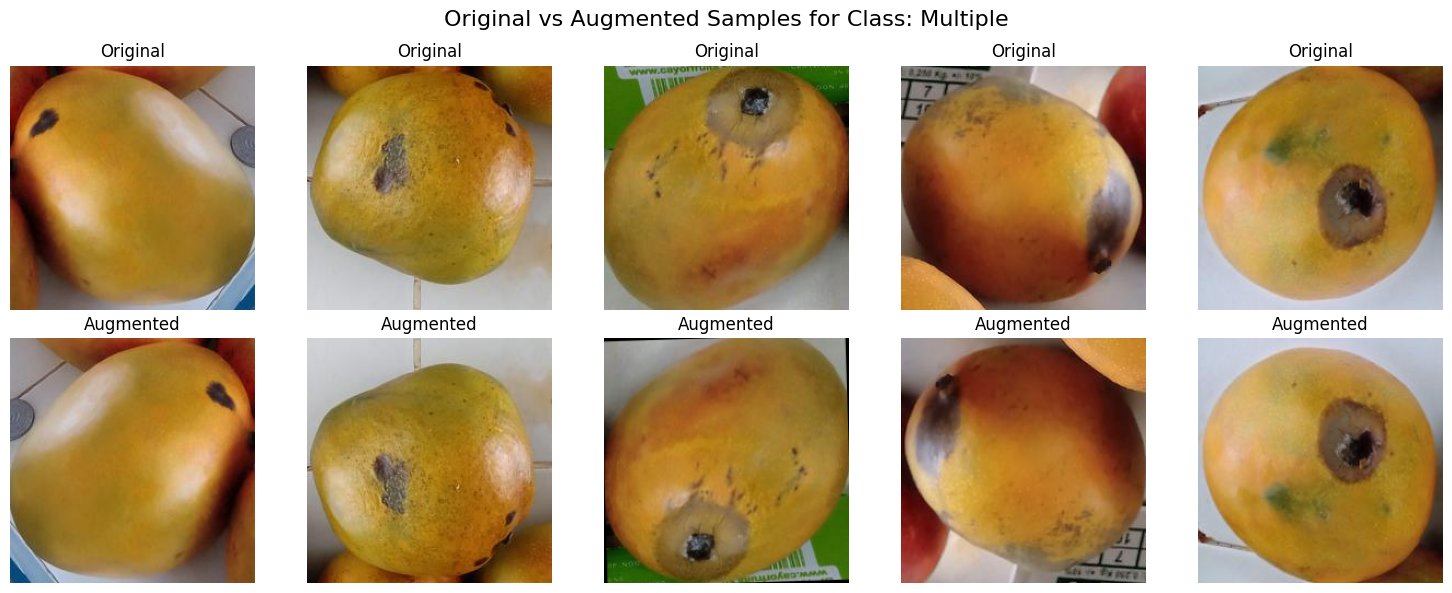

In [ ]:
visualize_leaf_class_augments(fruit_train_dir, class_specific_fruit_transforms, samples_per_class=5)


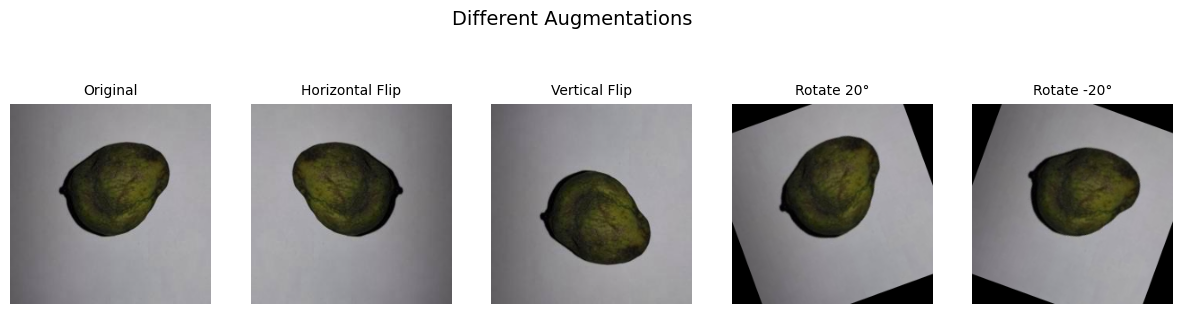

In [ ]:
show_named_augmentations(fruit_img)


In [ ]:

#  Helper: wrap single transform into dictionary per class
def wrap_transform(transform):
    return lambda image: transform(image=image)["image"]

leaf_train_ds = LeafDataset(root_dir=leaf_train_dir, transform_dict=wrapped_class_specific_transforms)

leaf_val_ds = LeafDataset(
    root_dir=leaf_val_dir,
    transform_dict={cls: wrapped_val_test_transform for cls in os.listdir(leaf_val_dir)}
)

leaf_test_ds = LeafDataset(
    root_dir=leaf_test_dir,
    transform_dict={cls: wrapped_val_test_transform for cls in os.listdir(leaf_test_dir)}
)

fruit_train_ds = FruitDataset(root_dir=fruit_train_dir, transform_dict=wrapped_class_specific_fruit_transforms)

fruit_val_ds = FruitDataset(
    root_dir=fruit_val_dir,
    transform_dict={cls: wrapped_val_test_transform for cls in os.listdir(fruit_val_dir)}
)

fruit_test_ds = FruitDataset(
    root_dir=fruit_test_dir,
    transform_dict={cls: wrapped_val_test_transform for cls in os.listdir(fruit_test_dir)}
)


#  DataLoaders
BATCH_SIZE = 32
leaf_train_loader = DataLoader(leaf_train_ds, batch_size=BATCH_SIZE, shuffle=True)
leaf_val_loader   = DataLoader(leaf_val_ds, batch_size=BATCH_SIZE, shuffle=False)
leaf_test_loader  = DataLoader(leaf_test_ds, batch_size=BATCH_SIZE, shuffle=False)

fruit_train_loader = DataLoader(fruit_train_ds, batch_size=BATCH_SIZE, shuffle=True)
fruit_val_loader   = DataLoader(fruit_val_ds, batch_size=BATCH_SIZE, shuffle=False)
fruit_test_loader  = DataLoader(fruit_test_ds, batch_size=BATCH_SIZE, shuffle=False)

#  Check shape of batches
leaf_batch = next(iter(leaf_train_loader))
fruit_batch = next(iter(fruit_train_loader))

print(f"Leaf batch: images {leaf_batch[0].shape}, labels {leaf_batch[1].shape}")
print(f"Fruit batch: images {fruit_batch[0].shape}, labels {fruit_batch[1].shape}")


Leaf batch: images torch.Size([32, 3, 224, 224]), labels torch.Size([32])
Fruit batch: images torch.Size([32, 3, 224, 224]), labels torch.Size([32])


In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models


def get_model(model_name="resnet18", num_classes=4, pretrained=True):
    if model_name == "resnet18":
        model = models.resnet18(pretrained=pretrained)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    elif model_name == "resnet50":
        model = models.resnet50(pretrained=pretrained)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    elif model_name == "mobilenet_v2":
        model = models.mobilenet_v2(pretrained=pretrained)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(pretrained=pretrained)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

    else:
        raise ValueError("Unsupported model name!")

    return model


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

leaf_model = get_model("resnet18").to(device)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


In [ ]:
!pip install torchsummary
from torchsummary import summary
summary(leaf_model, (3, 224, 224))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]          36,864
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
       BasicBlock-11           [-1, 64, 56, 56]               0
           Conv2d-12           [-1, 64, 56, 56]          36,864
      BatchNorm2d-13           [-1, 64, 56, 56]             128
             ReLU-14           [-1, 64,

In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(leaf_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


In [ ]:
def train_model(model, criterion, optimizer, train_loader, val_loader,
                epochs=10, model_name="model", save_dir="/content/drive/MyDrive/MangoProject/Models"):

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    best_acc = 0.0

    # Make sure save path exists
    os.makedirs(save_dir, exist_ok=True)
    best_model_path = os.path.join(save_dir, f"best_{model_name}.pth")

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / len(train_loader)
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= len(val_loader)
        val_acc = val_correct / val_total
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        print(f"Epoch [{epoch+1}/{epochs}] "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} "
              f"| Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

        # Save best model with dynamic name
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), best_model_path)
            print(f"✅ Best model saved to: {best_model_path}")

    return train_losses, val_losses, train_accs, val_accs


In [ ]:
def plot_training_curves(train_losses, val_losses, train_accs, val_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label="Train Loss")
    plt.plot(epochs, val_losses, label="Val Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Loss Curve")
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, label="Train Acc")
    plt.plot(epochs, val_accs, label="Val Acc")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.title("Accuracy Curve")
    plt.legend()

    plt.tight_layout()
    plt.show()


In [ ]:


class_names = ['Anthracnose', 'Bacterial_Black_Spot', 'Healthy', 'Multiple']

def evaluate_model(model, test_loader, model_name):
    model.eval()
    y_true, y_pred, y_scores = [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_scores.extend(probs.cpu().numpy())

    y_true_np = np.array(y_true)
    y_pred_np = np.array(y_pred)

    # Accuracy
    acc = np.mean(y_true_np == y_pred_np)
    print(f"\n✅ Accuracy: {acc:.4f}")

    # Precision, Recall, F1
    precision = precision_score(y_true_np, y_pred_np, average='macro')
    recall = recall_score(y_true_np, y_pred_np, average='macro')
    f1 = f1_score(y_true_np, y_pred_np, average='macro')
    print(f"🎯 Precision: {precision:.4f}")
    print(f"🔁 Recall: {recall:.4f}")
    print(f"📏 F1 Score: {f1:.4f}")

    # BER
    report = classification_report(y_true, y_pred, output_dict=True, target_names=class_names)
    recalls = [report[cls]["recall"] for cls in class_names]
    ber = np.mean([1 - r for r in recalls])
    print(f"📉 Balanced Error Rate (BER): {ber:.4f}")

    # Classification report
    print("\n📝 Detailed Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion matrix
    # Confusion matrix with bold annotations and model name in title
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))

    sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 14, "weight": "medium"},
            )

    # Bold and dynamic title with model name
    plt.xlabel('Predicted', fontsize=13)
    plt.ylabel('True', fontsize=13)
    plt.title(f"Confusion Matrix - {model_name}", fontsize=14)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.tight_layout()
    plt.show()


    # ROC AUC
    try:
        roc_auc = roc_auc_score(y_true, y_scores, multi_class='ovr')
        print(f"\n📈 ROC AUC Score: {roc_auc:.4f}")
    except:
        print("⚠️ ROC AUC could not be calculated (likely due to missing class probability).")

    # Cohen’s Kappa
    kappa = cohen_kappa_score(y_true, y_pred)
    print(f"🧮 Cohen’s Kappa: {kappa:.4f}")

    # MCC
    mcc = matthews_corrcoef(y_true, y_pred)
    print(f"📌 Matthews CorrCoef (MCC): {mcc:.4f}")


## Training Loop for ResNet18 on Leaf Dataset



In [ ]:
# Train the model and store history
train_losses, val_losses, train_accs, val_accs = train_model(
    model=leaf_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=leaf_train_loader,
    val_loader=leaf_val_loader,
    epochs=10,
    model_name="resNet18_leaf"
)


Epoch [1/10] Train Loss: 0.3470 | Val Loss: 0.1251 | Train Acc: 0.8894 | Val Acc: 0.9630
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet18_leaf.pth
Epoch [2/10] Train Loss: 0.0930 | Val Loss: 0.0851 | Train Acc: 0.9690 | Val Acc: 0.9687
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet18_leaf.pth
Epoch [3/10] Train Loss: 0.0604 | Val Loss: 0.0912 | Train Acc: 0.9805 | Val Acc: 0.9630
Epoch [4/10] Train Loss: 0.0395 | Val Loss: 0.0507 | Train Acc: 0.9884 | Val Acc: 0.9744
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet18_leaf.pth
Epoch [5/10] Train Loss: 0.0461 | Val Loss: 0.1122 | Train Acc: 0.9848 | Val Acc: 0.9687
Epoch [6/10] Train Loss: 0.0433 | Val Loss: 0.0614 | Train Acc: 0.9842 | Val Acc: 0.9772
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet18_leaf.pth
Epoch [7/10] Train Loss: 0.0262 | Val Loss: 0.1342 | Train Acc: 0.9903 | Val Acc: 0.9544
Epoch [8/10] Train Lo

In [ ]:
# import cv2
# import os

# def delete_broken_images(root_dir):
#     count = 0
#     for class_name in os.listdir(root_dir):
#         class_path = os.path.join(root_dir, class_name)
#         for img_file in os.listdir(class_path):
#             img_path = os.path.join(class_path, img_file)
#             try:
#                 img = cv2.imread(img_path)
#                 if img is None:
#                     os.remove(img_path)
#                     count += 1
#                     print(f"[REMOVED] {img_path}")
#             except Exception as e:
#                 print(f"[ERROR] {img_path}: {e}")
#     print(f"\n✅ Done. Total broken images removed: {count}")

# # Run this for both datasets
# delete_broken_images("/content/drive/MyDrive/datasets/Split_Leaves/train")
# delete_broken_images("/content/drive/MyDrive/datasets/Mango/Split_Fruits/train")



[REMOVED] /content/drive/MyDrive/datasets/Split_Leaves/train/Bacterial_Black_Spot/IMG_20211106_135654 (Custom).jpg

✅ Done. Total broken images removed: 1

✅ Done. Total broken images removed: 0


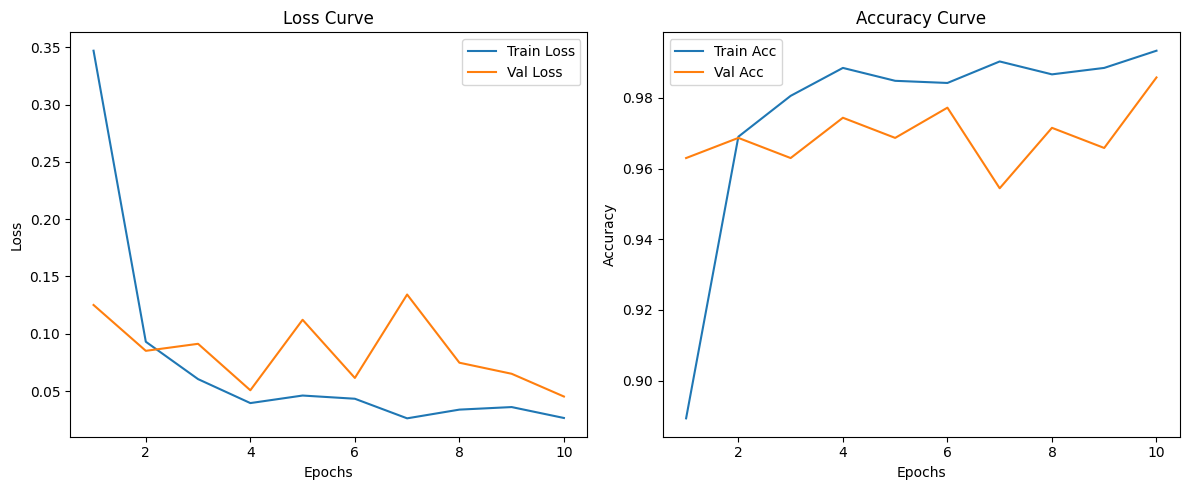

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)



✅ Accuracy: 0.9748
🎯 Precision: 0.9617
🔁 Recall: 0.9712
📏 F1 Score: 0.9663
📉 Balanced Error Rate (BER): 0.0288

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.92      0.94      0.93        50
Bacterial_Black_Spot       0.93      0.96      0.95        55
             Healthy       1.00      1.00      1.00        38
            Multiple       1.00      0.98      0.99       214

            accuracy                           0.97       357
           macro avg       0.96      0.97      0.97       357
        weighted avg       0.98      0.97      0.97       357



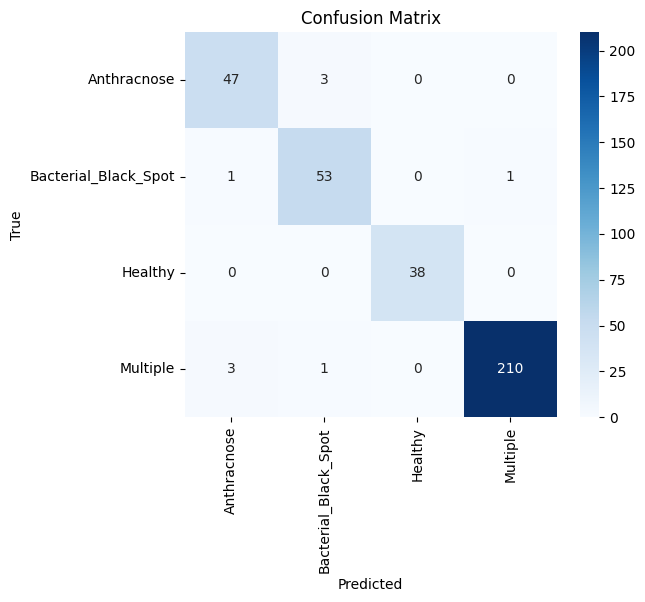


📈 ROC AUC Score: 0.9989
🧮 Cohen’s Kappa: 0.9573
📌 Matthews CorrCoef (MCC): 0.9574


In [ ]:
# Load the best model and evaluate
leaf_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_resNet18_leaf.pth"))
leaf_model.to(device)
evaluate_model(leaf_model, leaf_test_loader)


# Training Loop for Resnet50

In [ ]:
# import os
# import re

# def sanitize_filename(name):
#     # Replace problematic characters with underscores or nothing
#     name = re.sub(r'[(){}\[\]\'\"!@#$%^&*?,]', '_', name)
#     name = re.sub(r'__+', '_', name)  # Remove duplicate underscores
#     return name

# def rename_problematic_files(root_dir):
#     renamed_count = 0
#     for root, dirs, files in os.walk(root_dir):
#         for filename in files:
#             if any(char in filename for char in '()[]{}\'\"!@#$%^&*,'):
#                 old_path = os.path.join(root, filename)
#                 new_filename = sanitize_filename(filename)
#                 new_path = os.path.join(root, new_filename)
#                 if old_path != new_path:
#                     os.rename(old_path, new_path)
#                     print(f"Renamed:\n  {old_path} \n→ {new_path}\n")
#                     renamed_count += 1
#     print(f"✅ Total files renamed: {renamed_count}")

# # 👉 Use your dataset folder here
# rename_problematic_files("/content/drive/MyDrive/datasets/Split_Leaves")


✅ Total files renamed: 0


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

leaf_model = get_model("resnet50", num_classes=4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 104MB/s]


In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(leaf_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


In [ ]:
leaf_model.to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:

train_losses, val_losses, train_accs, val_accs = train_model(
    model=leaf_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=leaf_train_loader,
    val_loader=leaf_val_loader,
    epochs=10,
    model_name="resNet50_leaf"
)


Epoch [1/10] Train Loss: 0.3146 | Val Loss: 0.1395 | Train Acc: 0.9021 | Val Acc: 0.9687
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet50_leaf.pth
Epoch [2/10] Train Loss: 0.1087 | Val Loss: 0.1194 | Train Acc: 0.9672 | Val Acc: 0.9601
Epoch [3/10] Train Loss: 0.0645 | Val Loss: 0.0801 | Train Acc: 0.9818 | Val Acc: 0.9744
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet50_leaf.pth
Epoch [4/10] Train Loss: 0.0424 | Val Loss: 0.0519 | Train Acc: 0.9866 | Val Acc: 0.9829
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet50_leaf.pth
Epoch [5/10] Train Loss: 0.0613 | Val Loss: 0.1112 | Train Acc: 0.9805 | Val Acc: 0.9715
Epoch [6/10] Train Loss: 0.0414 | Val Loss: 0.0634 | Train Acc: 0.9854 | Val Acc: 0.9886
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resNet50_leaf.pth
Epoch [7/10] Train Loss: 0.0402 | Val Loss: 0.0815 | Train Acc: 0.9854 | Val Acc: 0.9744
Epoch [8/10] Train Lo

In [ ]:
# import os
# import cv2

# def remove_corrupt_images(folder_path):
#     removed = 0
#     for root, _, files in os.walk(folder_path):
#         for file in files:
#             path = os.path.join(root, file)
#             try:
#                 img = cv2.imread(path)
#                 if img is None:
#                     print(f"❌ Removing corrupt image: {path}")
#                     os.remove(path)
#                     removed += 1
#             except Exception as e:
#                 print(f"❌ Error with {path}: {e}")
#                 os.remove(path)
#                 removed += 1
#     print(f"\n✅ Removed {removed} corrupt/unreadable images.")

# # Your folder
# remove_corrupt_images("/content/drive/MyDrive/datasets/Split_Leaves")


❌ Removing corrupt image: /content/drive/MyDrive/datasets/Split_Leaves/train/Bacterial_Black_Spot/IMG_20211106_135646_Custom.jpg

✅ Removed 1 corrupt/unreadable images.


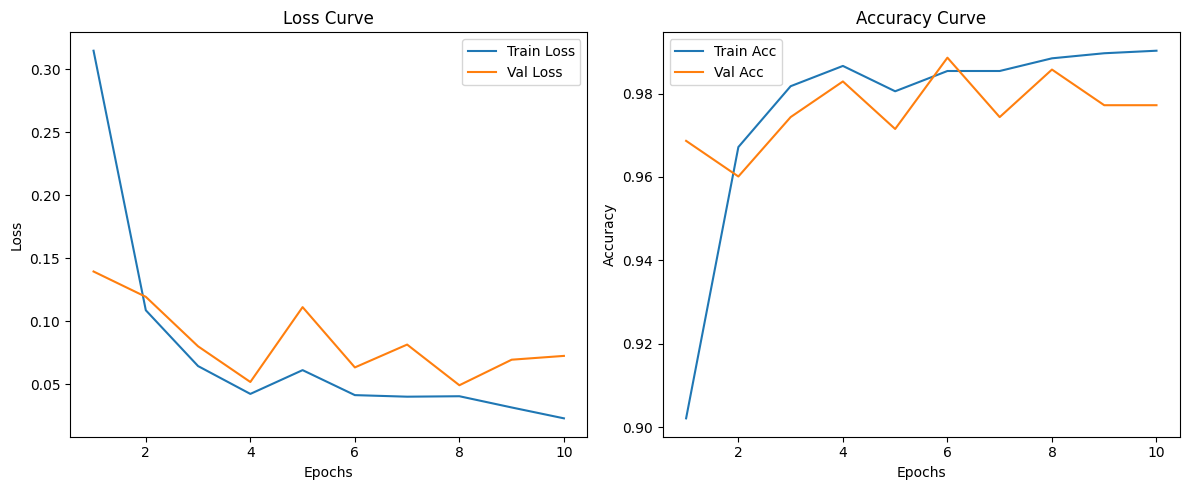

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)



✅ Accuracy: 0.9776
🎯 Precision: 0.9722
🔁 Recall: 0.9661
📏 F1 Score: 0.9689
📉 Balanced Error Rate (BER): 0.0339

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.94      0.96      0.95        50
Bacterial_Black_Spot       0.96      0.91      0.93        55
             Healthy       1.00      1.00      1.00        38
            Multiple       0.99      1.00      0.99       214

            accuracy                           0.98       357
           macro avg       0.97      0.97      0.97       357
        weighted avg       0.98      0.98      0.98       357



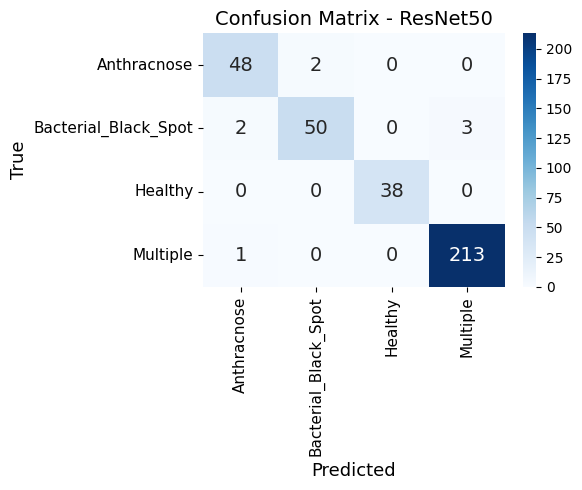


📈 ROC AUC Score: 0.9993
🧮 Cohen’s Kappa: 0.9616
📌 Matthews CorrCoef (MCC): 0.9617


In [ ]:
# Load the best model and evaluate
leaf_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_resNet50_leaf.pth"))
leaf_model.to(device)
evaluate_model(leaf_model, leaf_test_loader,model_name="ResNet50")


## Training mobilenet_v2 on LeafDataset

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
leaf_model = get_model("mobilenet_v2", num_classes=4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100%|██████████| 13.6M/13.6M [00:00<00:00, 115MB/s] 


In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(leaf_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


In [ ]:
leaf_model.to(device)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [ ]:

train_losses, val_losses, train_accs, val_accs = train_model(
    model=leaf_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=leaf_train_loader,
    val_loader=leaf_val_loader,
    epochs=10,
    model_name="mobilenet_v2_leaf"
)


Epoch [1/10] Train Loss: 0.4174 | Val Loss: 0.1341 | Train Acc: 0.8705 | Val Acc: 0.9544
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_leaf.pth
Epoch [2/10] Train Loss: 0.1073 | Val Loss: 0.0732 | Train Acc: 0.9666 | Val Acc: 0.9772
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_leaf.pth
Epoch [3/10] Train Loss: 0.0607 | Val Loss: 0.0718 | Train Acc: 0.9836 | Val Acc: 0.9801
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_leaf.pth
Epoch [4/10] Train Loss: 0.0513 | Val Loss: 0.0551 | Train Acc: 0.9836 | Val Acc: 0.9829
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_leaf.pth
Epoch [5/10] Train Loss: 0.0574 | Val Loss: 0.0828 | Train Acc: 0.9812 | Val Acc: 0.9772
Epoch [6/10] Train Loss: 0.0410 | Val Loss: 0.0674 | Train Acc: 0.9866 | Val Acc: 0.9744
Epoch [7/10] Train Loss: 0.0342 | Val Loss: 0.0707 | Train Acc: 0.9915 | Val Acc: 0.9715
Epoch

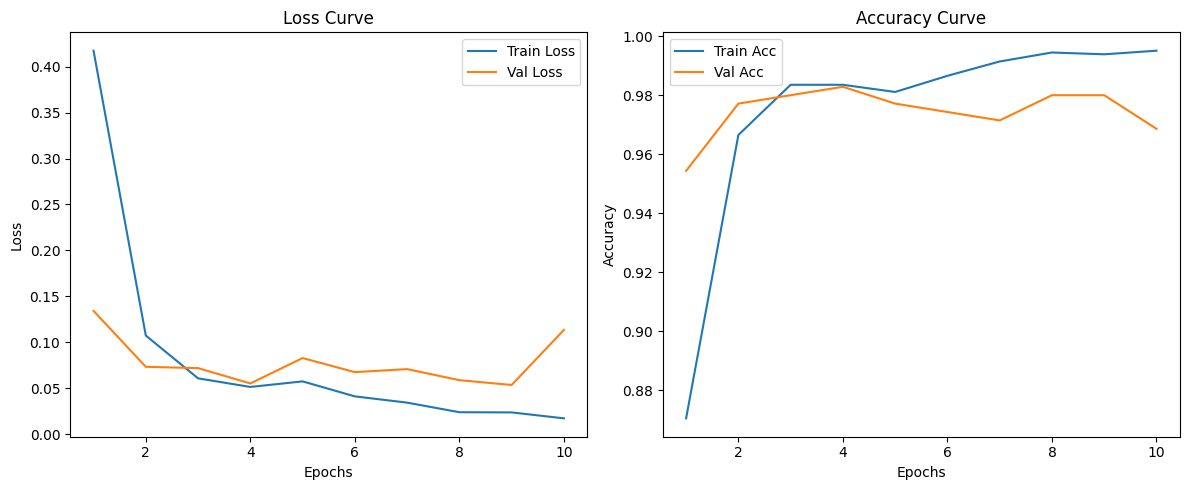

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)



✅ Accuracy: 0.9888
🎯 Precision: 0.9845
🔁 Recall: 0.9881
📏 F1 Score: 0.9863
📉 Balanced Error Rate (BER): 0.0119

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.96      0.98      0.97        50
Bacterial_Black_Spot       0.98      0.98      0.98        55
             Healthy       1.00      1.00      1.00        38
            Multiple       1.00      0.99      0.99       214

            accuracy                           0.99       357
           macro avg       0.98      0.99      0.99       357
        weighted avg       0.99      0.99      0.99       357



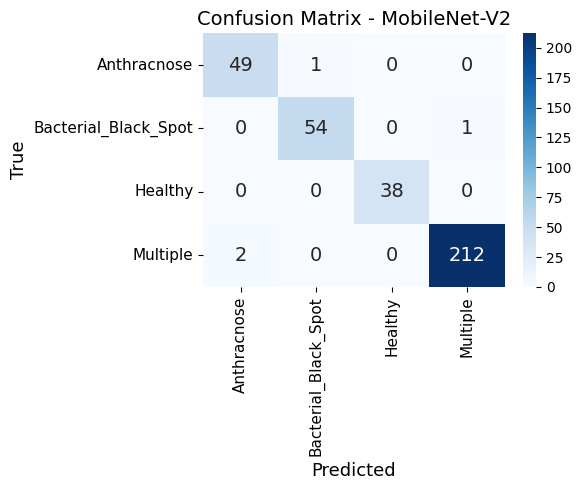


📈 ROC AUC Score: 0.9994
🧮 Cohen’s Kappa: 0.9809
📌 Matthews CorrCoef (MCC): 0.9809


In [ ]:
# Load the best model and evaluate
leaf_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_leaf.pth"))
leaf_model.to(device)
evaluate_model(leaf_model, leaf_test_loader,model_name="MobileNet-V2")


## Training EfficientNet B0 on Leaf Model

In [ ]:
# efficientnet_b0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
leaf_model = get_model("efficientnet_b0", num_classes=4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 113MB/s] 


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(leaf_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


In [ ]:
leaf_model.to(device)


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
# Train the model and store history
train_losses, val_losses, train_accs, val_accs = train_model(
    model=leaf_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=leaf_train_loader,
    val_loader=leaf_val_loader,
    epochs=10,
    model_name="efficientnet_b0_leaf"
)


Epoch [1/10] Train Loss: 0.7712 | Val Loss: 0.3608 | Train Acc: 0.7660 | Val Acc: 0.9117
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_leaf.pth
Epoch [2/10] Train Loss: 0.2789 | Val Loss: 0.2808 | Train Acc: 0.9216 | Val Acc: 0.9373
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_leaf.pth
Epoch [3/10] Train Loss: 0.1342 | Val Loss: 0.2609 | Train Acc: 0.9666 | Val Acc: 0.9573
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_leaf.pth
Epoch [4/10] Train Loss: 0.1011 | Val Loss: 0.0733 | Train Acc: 0.9684 | Val Acc: 0.9772
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_leaf.pth
Epoch [5/10] Train Loss: 0.0827 | Val Loss: 0.0703 | Train Acc: 0.9769 | Val Acc: 0.9772
Epoch [6/10] Train Loss: 0.0739 | Val Loss: 0.0670 | Train Acc: 0.9757 | Val Acc: 0.9801
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientne

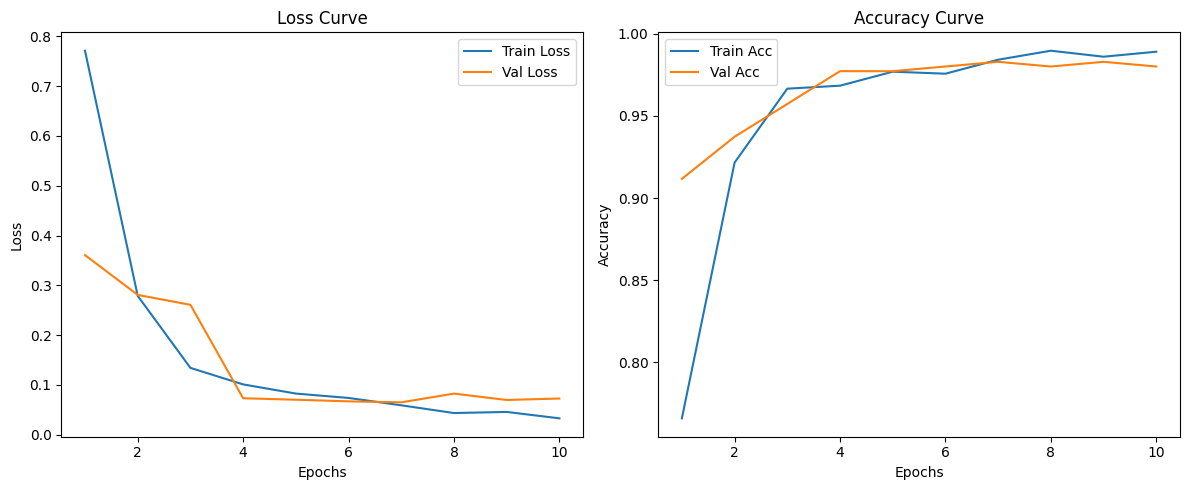

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)



✅ Accuracy: 0.9832
🎯 Precision: 0.9771
🔁 Recall: 0.9786
📏 F1 Score: 0.9778
📉 Balanced Error Rate (BER): 0.0214

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.98      0.96      0.97        50
Bacterial_Black_Spot       0.96      0.96      0.96        55
             Healthy       0.97      1.00      0.99        38
            Multiple       0.99      0.99      0.99       214

            accuracy                           0.98       357
           macro avg       0.98      0.98      0.98       357
        weighted avg       0.98      0.98      0.98       357



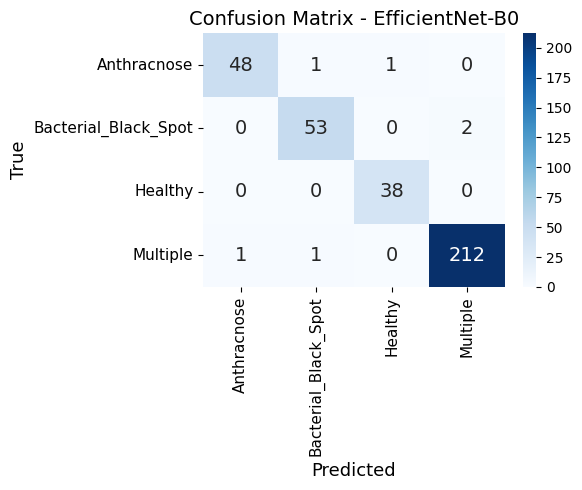


📈 ROC AUC Score: 0.9986
🧮 Cohen’s Kappa: 0.9713
📌 Matthews CorrCoef (MCC): 0.9713


In [ ]:
# Load the best model and evaluate
leaf_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_leaf.pth"))
leaf_model.to(device)
evaluate_model(leaf_model, leaf_test_loader,model_name="EfficientNet-B0")


## Training ConvNext on Leaf Model

In [ ]:
leaf_model  = models.convnext_tiny(pretrained=True)  # or convnext_base, convnext_small, etc.

# Modify final classification head
num_classes = 4  # Your number of classes (Anthracnose, BBS, Healthy, Multiple)
leaf_model.classifier[2] = nn.Linear(leaf_model.classifier[2].in_features, num_classes)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1`. You can also use `weights=ConvNeXt_Tiny_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:00<00:00, 127MB/s] 


In [ ]:


criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(leaf_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [ ]:
leaf_model.to(device)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

In [ ]:
train_losses, val_losses, train_accs, val_accs = train_model(
    model=leaf_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=leaf_train_loader,
    val_loader=leaf_val_loader,
    epochs=10,
    model_name="ConNext_leaf"
)


Epoch [1/10] Train Loss: 0.3401 | Val Loss: 0.0817 | Train Acc: 0.8796 | Val Acc: 0.9772
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_ConNext_leaf.pth
Epoch [2/10] Train Loss: 0.0604 | Val Loss: 0.0526 | Train Acc: 0.9830 | Val Acc: 0.9829
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_ConNext_leaf.pth
Epoch [3/10] Train Loss: 0.0367 | Val Loss: 0.0909 | Train Acc: 0.9891 | Val Acc: 0.9744
Epoch [4/10] Train Loss: 0.0306 | Val Loss: 0.0558 | Train Acc: 0.9921 | Val Acc: 0.9829
Epoch [5/10] Train Loss: 0.0120 | Val Loss: 0.0526 | Train Acc: 0.9964 | Val Acc: 0.9772
Epoch [6/10] Train Loss: 0.0094 | Val Loss: 0.0670 | Train Acc: 0.9970 | Val Acc: 0.9801
Epoch [7/10] Train Loss: 0.0352 | Val Loss: 0.0257 | Train Acc: 0.9909 | Val Acc: 0.9886
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_ConNext_leaf.pth
Epoch [8/10] Train Loss: 0.0179 | Val Loss: 0.0423 | Train Acc: 0.9921 | Val Acc: 0.9886
Epoch [9/10] Train Loss:

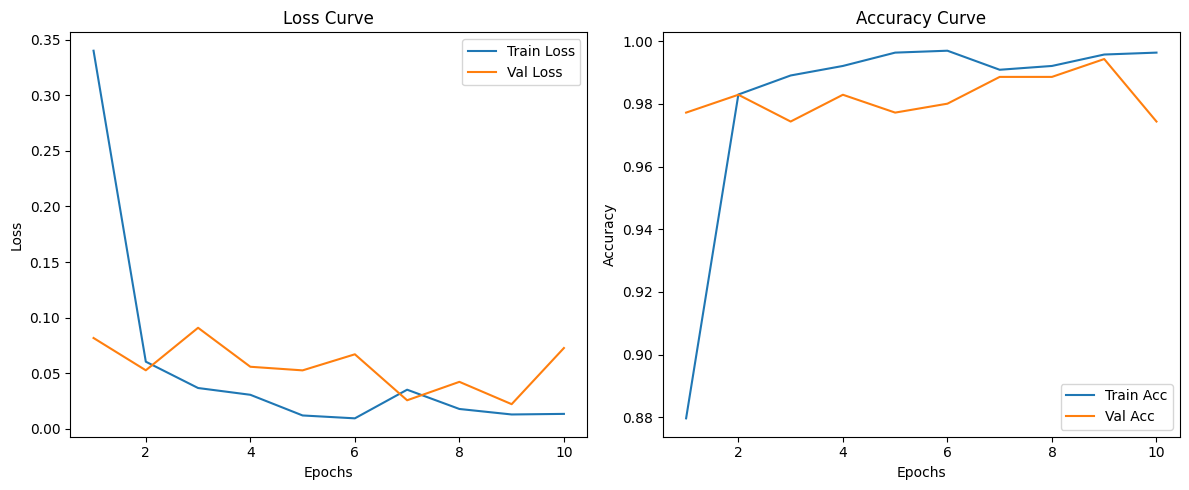

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)


In [ ]:
!ls /content/drive/MyDrive/MangoProject/Models/

best_ConNext_fruit.pth		best_model.pth
best_ConNext_leaf.pth		best_resnet_18_fruit.pth
best_efficientnet_b0_fruit.pth	best_resNet18_leaf.pth
best_efficientnet_b0_leaf.pth	best_resnet50_fruit.pth
best_mobilenet_v2_fruit.pth	best_resNet50_leaf.pth
best_mobilenet_v2_leaf.pth



✅ Accuracy: 0.9804
🎯 Precision: 0.9771
🔁 Recall: 0.9706
📏 F1 Score: 0.9738
📉 Balanced Error Rate (BER): 0.0294

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.96      0.96      0.96        50
Bacterial_Black_Spot       0.96      0.93      0.94        55
             Healthy       1.00      1.00      1.00        38
            Multiple       0.99      1.00      0.99       214

            accuracy                           0.98       357
           macro avg       0.98      0.97      0.97       357
        weighted avg       0.98      0.98      0.98       357



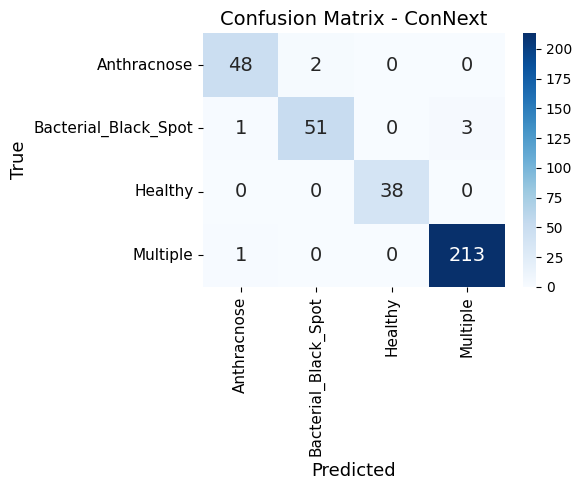


📈 ROC AUC Score: 0.9995
🧮 Cohen’s Kappa: 0.9664
📌 Matthews CorrCoef (MCC): 0.9665


In [ ]:
# Load the best model and evaluate
leaf_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_ConNext_leaf.pth"))
leaf_model.to(device)
evaluate_model(leaf_model, leaf_test_loader,model_name="ConNext")


# Fruit Dataset Training

## Fruit Dataset Training on the Resnet18

In [ ]:
fruit_model = get_model("resnet18",  num_classes=4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(fruit_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [ ]:
fruit_model.to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
train_losses, val_losses, train_accs, val_accs = train_model(
    model=fruit_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=fruit_train_loader,
    val_loader=fruit_val_loader,
    epochs=10,
    model_name="resnet_18_fruit"
)

Epoch [1/10] Train Loss: 0.9069 | Val Loss: 0.9560 | Train Acc: 0.6464 | Val Acc: 0.5000
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth
Epoch [2/10] Train Loss: 0.1702 | Val Loss: 0.5809 | Train Acc: 0.9607 | Val Acc: 0.7667
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth
Epoch [3/10] Train Loss: 0.0653 | Val Loss: 0.6022 | Train Acc: 0.9857 | Val Acc: 0.7833
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth
Epoch [4/10] Train Loss: 0.0261 | Val Loss: 0.1090 | Train Acc: 0.9964 | Val Acc: 0.9667
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth
Epoch [5/10] Train Loss: 0.0197 | Val Loss: 0.0208 | Train Acc: 1.0000 | Val Acc: 1.0000
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth
Epoch [6/10] Train Loss: 0.0399 | Val Loss: 0.0958 | Train Acc: 0.9893 | Val Acc: 0.9667
Epoch [7/10

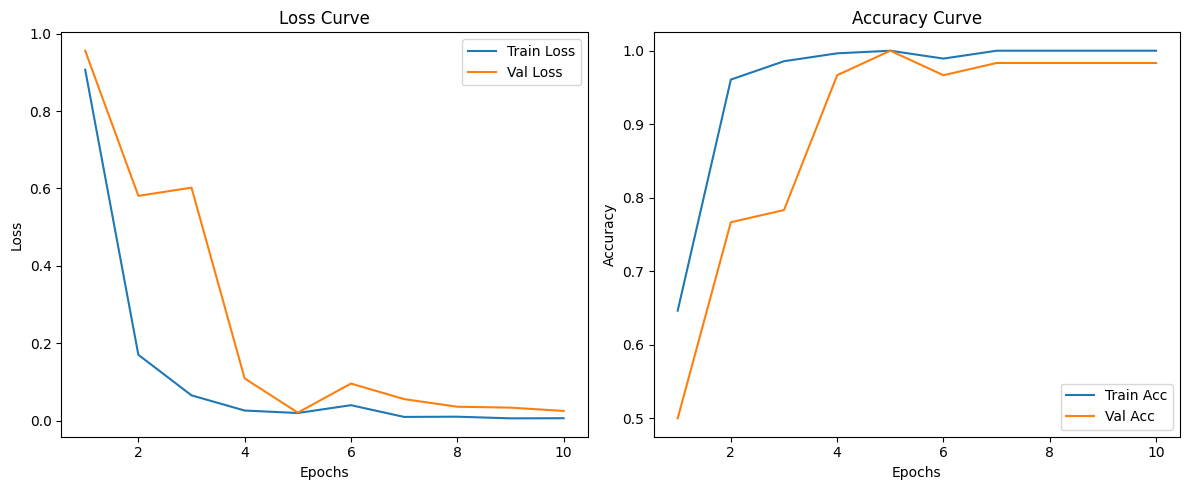

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)


✅ Accuracy: 0.9894
🎯 Precision: 0.9923
🔁 Recall: 0.9792
📏 F1 Score: 0.9852
📉 Balanced Error Rate (BER): 0.0208

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       1.00      0.92      0.96        36
Bacterial_Black_Spot       1.00      1.00      1.00       107
             Healthy       1.00      1.00      1.00        47
            Multiple       0.97      1.00      0.98        94

            accuracy                           0.99       284
           macro avg       0.99      0.98      0.99       284
        weighted avg       0.99      0.99      0.99       284



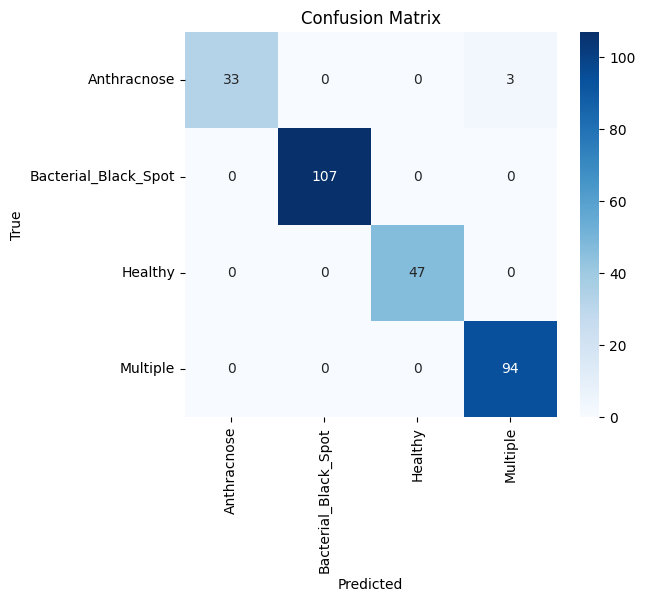


📈 ROC AUC Score: 0.9986
🧮 Cohen’s Kappa: 0.9850
📌 Matthews CorrCoef (MCC): 0.9851


In [ ]:
# Load the best model and evaluate
fruit_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth"))
fruit_model.to(device)
evaluate_model(fruit_model, fruit_test_loader)

## Training on ResNet50 on Fruit Dataset

In [ ]:
fruit_model = get_model("resnet50", num_classes=4)



/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(fruit_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


fruit_model.to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
# Train the model and store history
train_losses, val_losses, train_accs, val_accs = train_model(
    model=fruit_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=fruit_train_loader,
    val_loader=fruit_val_loader,
    epochs=10,
    model_name="resnet50_fruit"
)


Epoch [1/10] Train Loss: 0.7944 | Val Loss: 0.5930 | Train Acc: 0.7857 | Val Acc: 0.8667
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet50_fruit.pth
Epoch [2/10] Train Loss: 0.1775 | Val Loss: 0.1881 | Train Acc: 0.9607 | Val Acc: 0.9333
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet50_fruit.pth
Epoch [3/10] Train Loss: 0.0455 | Val Loss: 0.0454 | Train Acc: 0.9893 | Val Acc: 1.0000
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_resnet50_fruit.pth
Epoch [4/10] Train Loss: 0.0231 | Val Loss: 0.0747 | Train Acc: 0.9929 | Val Acc: 0.9833
Epoch [5/10] Train Loss: 0.0166 | Val Loss: 0.0226 | Train Acc: 0.9964 | Val Acc: 1.0000
Epoch [6/10] Train Loss: 0.0653 | Val Loss: 0.0111 | Train Acc: 0.9786 | Val Acc: 1.0000
Epoch [7/10] Train Loss: 0.0400 | Val Loss: 0.1553 | Train Acc: 0.9821 | Val Acc: 0.9500
Epoch [8/10] Train Loss: 0.0690 | Val Loss: 0.0264 | Train Acc: 0.9821 | Val Acc: 1.0000
Epoch [9/10] Train

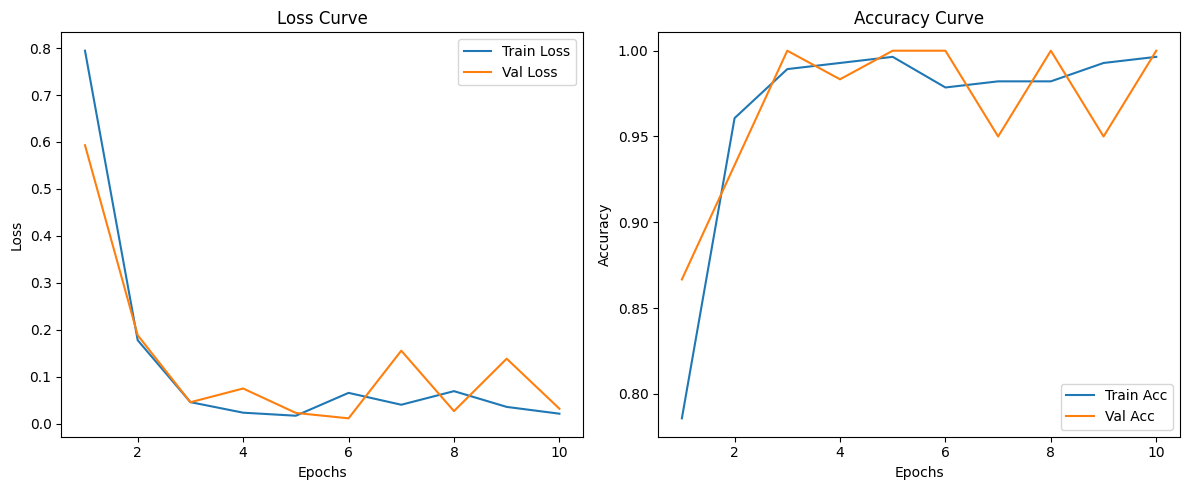

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)


✅ Accuracy: 0.9824
🎯 Precision: 0.9778
🔁 Recall: 0.9738
📏 F1 Score: 0.9758
📉 Balanced Error Rate (BER): 0.0262

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.94      0.92      0.93        36
Bacterial_Black_Spot       1.00      1.00      1.00       107
             Healthy       1.00      1.00      1.00        47
            Multiple       0.97      0.98      0.97        94

            accuracy                           0.98       284
           macro avg       0.98      0.97      0.98       284
        weighted avg       0.98      0.98      0.98       284



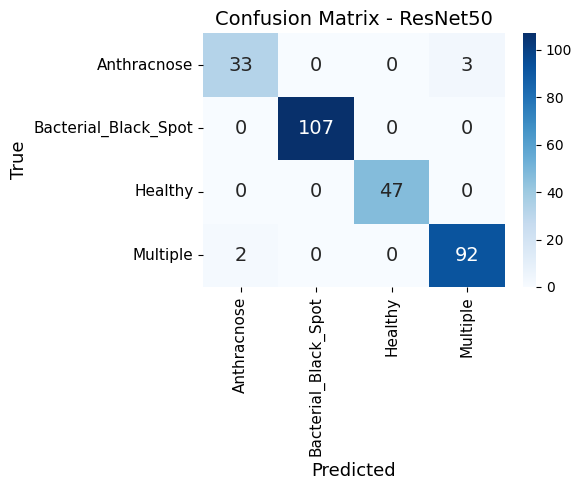


📈 ROC AUC Score: 0.9925
🧮 Cohen’s Kappa: 0.9750
📌 Matthews CorrCoef (MCC): 0.9750


In [ ]:
# Load the best model and evaluate
fruit_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_resnet50_fruit.pth"))
fruit_model.to(device)
evaluate_model(fruit_model, fruit_test_loader,model_name="ResNet50")


## Training MobileNet V2 on Fruit

In [ ]:
fruit_model = get_model("mobilenet_v2", num_classes=4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(fruit_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


fruit_model.to(device)



MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [ ]:
# Train the model and store history
train_losses, val_losses, train_accs, val_accs = train_model(
    model=fruit_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=fruit_train_loader,
    val_loader=fruit_val_loader,
    epochs=10,
    model_name="mobilenet_v2_fruit"
)


Epoch [1/10] Train Loss: 1.0298 | Val Loss: 1.2519 | Train Acc: 0.6321 | Val Acc: 0.5167
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth
Epoch [2/10] Train Loss: 0.4144 | Val Loss: 0.8644 | Train Acc: 0.9214 | Val Acc: 0.5667
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth
Epoch [3/10] Train Loss: 0.1755 | Val Loss: 0.4776 | Train Acc: 0.9679 | Val Acc: 0.7500
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth
Epoch [4/10] Train Loss: 0.0734 | Val Loss: 0.2690 | Train Acc: 0.9857 | Val Acc: 0.8667
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth
Epoch [5/10] Train Loss: 0.0562 | Val Loss: 0.1318 | Train Acc: 0.9893 | Val Acc: 0.9500
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth
Epoch [6/10] Train Loss: 0.0311 | Val Loss: 0.0760 | Train Acc: 0.9929 | Val Acc: 0.9

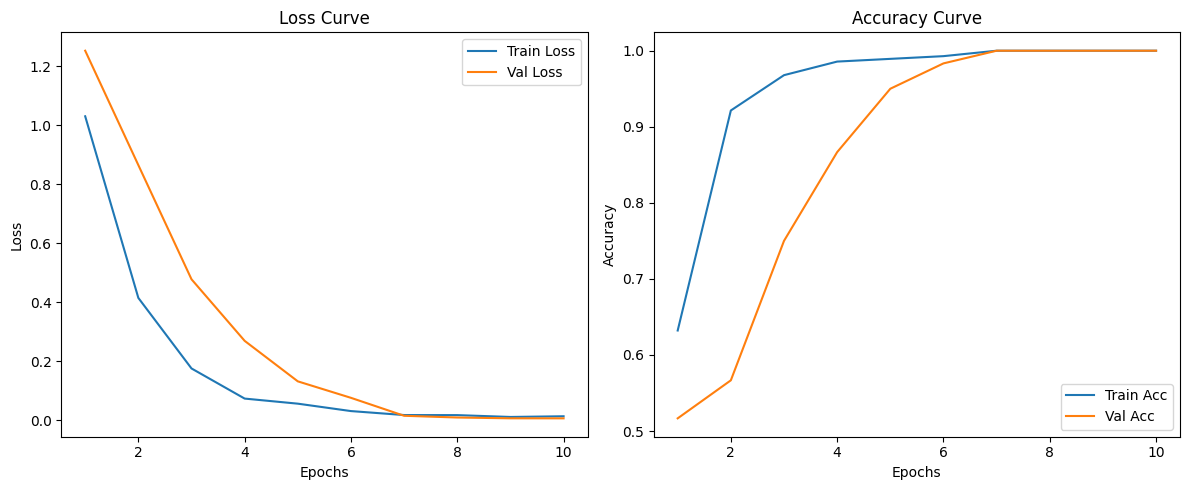

In [ ]:
# Plot loss and accuracy curves
plot_training_curves(train_losses, val_losses, train_accs, val_accs)


✅ Accuracy: 0.9965
🎯 Precision: 0.9974
🔁 Recall: 0.9931
📏 F1 Score: 0.9952
📉 Balanced Error Rate (BER): 0.0069

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       1.00      0.97      0.99        36
Bacterial_Black_Spot       1.00      1.00      1.00       107
             Healthy       1.00      1.00      1.00        47
            Multiple       0.99      1.00      0.99        94

            accuracy                           1.00       284
           macro avg       1.00      0.99      1.00       284
        weighted avg       1.00      1.00      1.00       284



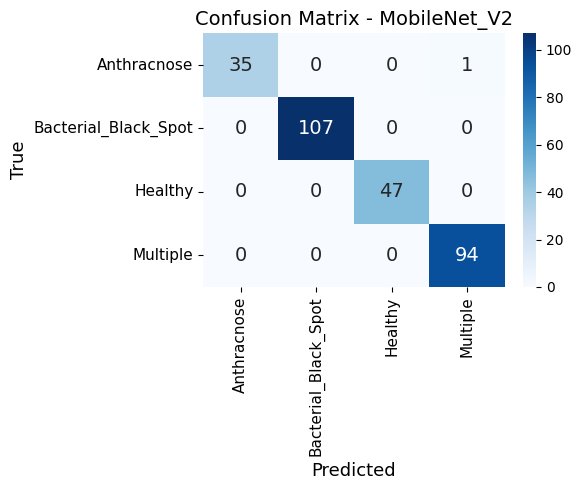


📈 ROC AUC Score: 0.9980
🧮 Cohen’s Kappa: 0.9950
📌 Matthews CorrCoef (MCC): 0.9950


In [ ]:
# Load the best model and evaluate
fruit_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth"))
fruit_model.to(device)
evaluate_model(fruit_model, fruit_test_loader,model_name="MobileNet_V2")



## Training efficientnet_b0 on Fruit

In [ ]:
# efficientnet_b0
fruit_model = get_model("efficientnet_b0", num_classes=4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(fruit_model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)


fruit_model.to(device)



EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
# Train the model and store history
train_losses, val_losses, train_accs, val_accs = train_model(
    model=fruit_model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=fruit_train_loader,
    val_loader=fruit_val_loader,
    epochs=10,
    model_name="efficientnet_b0_fruit"
)


Epoch [1/10] Train Loss: 1.3398 | Val Loss: 1.3505 | Train Acc: 0.3214 | Val Acc: 0.3000
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth
Epoch [2/10] Train Loss: 1.0069 | Val Loss: 1.1301 | Train Acc: 0.8214 | Val Acc: 0.5833
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth
Epoch [3/10] Train Loss: 0.7345 | Val Loss: 0.7965 | Train Acc: 0.8964 | Val Acc: 0.8333
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth
Epoch [4/10] Train Loss: 0.4745 | Val Loss: 0.4683 | Train Acc: 0.9357 | Val Acc: 0.9000
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth
Epoch [5/10] Train Loss: 0.3009 | Val Loss: 0.2445 | Train Acc: 0.9536 | Val Acc: 0.9500
✅ Best model saved to: /content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth
Epoch [6/10] Train Loss: 0.1881 | Val Loss: 0.1290 | Train Acc: 0.9750


✅ Accuracy: 0.9930
🎯 Precision: 0.9904
🔁 Recall: 0.9904
📏 F1 Score: 0.9904
📉 Balanced Error Rate (BER): 0.0096

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.97      0.97      0.97        36
Bacterial_Black_Spot       1.00      1.00      1.00       107
             Healthy       1.00      1.00      1.00        47
            Multiple       0.99      0.99      0.99        94

            accuracy                           0.99       284
           macro avg       0.99      0.99      0.99       284
        weighted avg       0.99      0.99      0.99       284



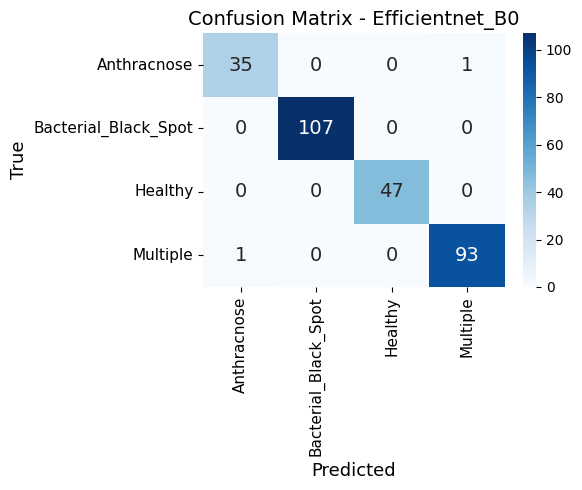


📈 ROC AUC Score: 0.9922
🧮 Cohen’s Kappa: 0.9900
📌 Matthews CorrCoef (MCC): 0.9900


In [ ]:
# Load the best model and evaluate
fruit_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth"))
fruit_model.to(device)
evaluate_model(fruit_model, fruit_test_loader,model_name="Efficientnet_B0")



In [ ]:
fruit_model  = models.convnext_tiny(pretrained=True)  # or convnext_base, convnext_small, etc.

# Modify final classification head
num_classes = 4  # Your number of classes (Anthracnose, BBS, Healthy, Multiple)
fruit_model.classifier[2] = nn.Linear(fruit_model.classifier[2].in_features, num_classes)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1`. You can also use `weights=ConvNeXt_Tiny_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



✅ Accuracy: 0.9824
🎯 Precision: 0.9824
🔁 Recall: 0.9745
📏 F1 Score: 0.9781
📉 Balanced Error Rate (BER): 0.0255

📝 Detailed Classification Report:
                      precision    recall  f1-score   support

         Anthracnose       0.97      0.92      0.94        36
Bacterial_Black_Spot       1.00      0.98      0.99       107
             Healthy       1.00      1.00      1.00        47
            Multiple       0.96      1.00      0.98        94

            accuracy                           0.98       284
           macro avg       0.98      0.97      0.98       284
        weighted avg       0.98      0.98      0.98       284



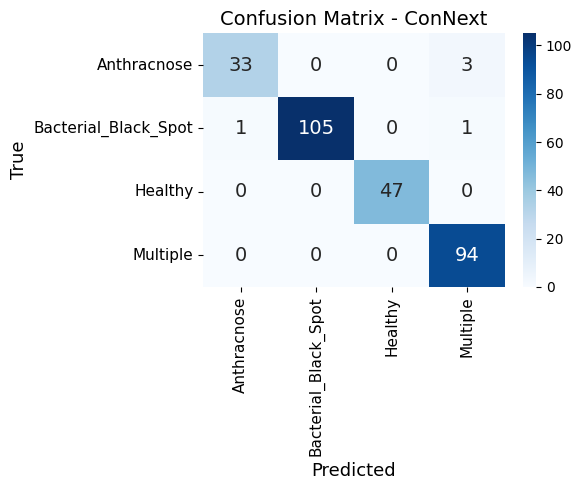


📈 ROC AUC Score: 0.9967
🧮 Cohen’s Kappa: 0.9750
📌 Matthews CorrCoef (MCC): 0.9752


In [ ]:
# Load the best model and evaluate
fruit_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_ConNext_fruit.pth"))
fruit_model.to(device)
evaluate_model(fruit_model, fruit_test_loader,model_name="ConNext")

